# Road Sign Detection — Dataset Preparation and Analysis

This project focuses on preparing a road sign detection dataset for training a YOLO object detection model.

The dataset contains 877 road images and their corresponding XML annotations.

### Objectives
- Explore and analyze the dataset.
- Visualize images and bounding boxes.
- Analyze road sign class distribution.
- Validate dataset quality.
- Convert Pascal VOC XML annotations into YOLO format.
- Split the dataset into training, validation, and test sets.
- Prepare the dataset for model training.

### Road Sign Classes
0. trafficlight
1. stop
2. speedlimit
3. crosswalk

## 1. Environment Setup

The required Python libraries are installed to support dataset downloading, image processing, XML annotation parsing, data analysis, and visualization.

In [4]:
!pip install -q kagglehub pandas matplotlib pillow

## 2. Dataset Download

The Road Sign Detection dataset is downloaded from Kaggle using the KaggleHub library.

Dataset source: https://www.kaggle.com/datasets/andrewmvd/road-sign-detection

The dataset contains two directories:
- `images/` — road images.
- `annotations/` — XML annotation files.


In [5]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "andrewmvd/road-sign-detection"
)

print("Dataset path:", dataset_path)
print("Files:", os.listdir(dataset_path))

100%|██████████| 218M/218M [00:03<00:00, 68.7MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/andrewmvd/road-sign-detection/versions/1
Files: ['annotations', 'images']


## 3. Dataset Structure Analysis

The dataset structure is examined by counting the number of images and XML annotation files.

The dataset contains 877 images and 877 XML annotations.

The matching filenames indicate that each image has a corresponding annotation file.


In [6]:
images_path = os.path.join(dataset_path, "images")
annotations_path = os.path.join(dataset_path, "annotations")

images = sorted([
    f for f in os.listdir(images_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

annotations = sorted([
    f for f in os.listdir(annotations_path)
    if f.lower().endswith(".xml")
])

print("Number of images:", len(images))
print("Number of annotations:", len(annotations))

print("\nFirst 5 images:", images[:5])
print("First 5 annotations:", annotations[:5])

Number of images: 877
Number of annotations: 877

First 5 images: ['road0.png', 'road1.png', 'road10.png', 'road100.png', 'road101.png']
First 5 annotations: ['road0.xml', 'road1.xml', 'road10.xml', 'road100.xml', 'road101.xml']


## 4. Image Visualization

A sample image is displayed to examine the visual characteristics of the dataset.

The selected image (`road0.png`) contains a traffic light and has a resolution of 267 × 400 pixels.

This step verifies that the image files can be successfully opened and displayed.


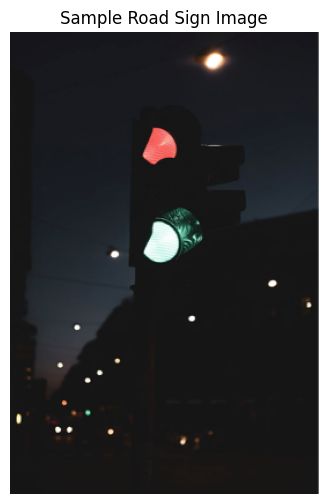

Image size: (267, 400)


In [7]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = os.path.join(images_path, images[0])

image = Image.open(image_path)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Sample Road Sign Image")
plt.axis("off")
plt.show()

print("Image size:", image.size)

## 5. XML Annotation Analysis

The dataset uses Pascal VOC XML annotations to describe road signs.

Each annotation contains the object class and its bounding box coordinates.

Bounding boxes are defined by four values:
- `xmin` — left boundary.
- `ymin` — top boundary.
- `xmax` — right boundary.
- `ymax` — bottom boundary.

These coordinates are used to locate objects within images.

In [8]:
import xml.etree.ElementTree as ET

xml_path = os.path.join(
    annotations_path,
    "road0.xml"
)

tree = ET.parse(xml_path)
root = tree.getroot()

print("Image:", root.findtext("filename"))

for obj in root.findall("object"):
    name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    print("Class:", name)
    print("Bounding box:", xmin, ymin, xmax, ymax)

Image: road0.png
Class: trafficlight
Bounding box: 98 62 208 232


## 6. Bounding Box Visualization

Bounding boxes are visualized using coordinates extracted from XML annotations.

A rectangle is drawn around the annotated object, and the corresponding class name is displayed.

This step helps verify the accuracy of object annotations.

The sample image successfully displays a bounding box around the traffic light.


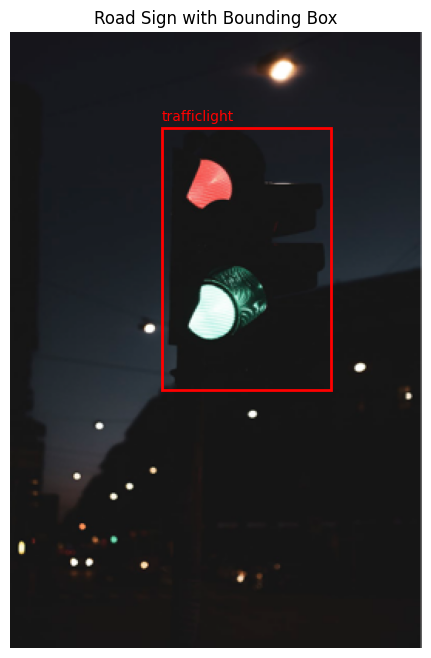

In [9]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(Image.open(os.path.join(images_path, "road0.png")))

for obj in root.findall("object"):
    name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.text(xmin, ymin - 5, name, color="red")

plt.title("Road Sign with Bounding Box")
plt.axis("off")
plt.show()

## 7. Class Distribution Analysis

The number of annotated objects is calculated for each road sign class.

The dataset contains 1,244 annotated objects distributed across four classes.

| Class | Number of Objects |
|---|---:|
| trafficlight | 170 |
| stop | 91 |
| speedlimit | 783 |
| crosswalk | 200 |

The dataset is imbalanced. Speed limit signs represent the largest class, while stop signs are the least represented.

This imbalance may affect model performance and should be considered during training.


In [10]:
from collections import Counter
import pandas as pd

class_counts = Counter()
objects_per_image = []

for annotation in annotations:
    xml_file = os.path.join(annotations_path, annotation)

    tree = ET.parse(xml_file)
    root = tree.getroot()

    objects = root.findall("object")
    objects_per_image.append(len(objects))

    for obj in objects:
        class_name = obj.findtext("name")
        class_counts[class_name] += 1

df_classes = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Count"]
)

print(df_classes)
print("\nTotal objects:", sum(class_counts.values()))
print("Average objects per image:",
      round(sum(objects_per_image) / len(objects_per_image), 2))

          Class  Count
0  trafficlight    170
1    speedlimit    783
2     crosswalk    200
3          stop     91

Total objects: 1244
Average objects per image: 1.42


### Class Distribution Visualization

A bar chart is generated to visualize the number of objects belonging to each class.

The visualization highlights the significant difference between the most common and least common road sign categories.


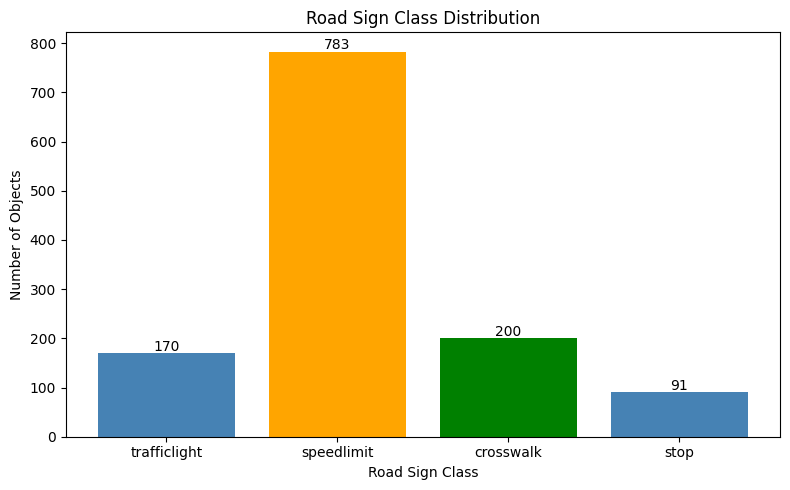

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_classes["Class"],
    df_classes["Count"],
    color=["steelblue", "orange", "green"]
)

plt.title("Road Sign Class Distribution")
plt.xlabel("Road Sign Class")
plt.ylabel("Number of Objects")

for i, count in enumerate(df_classes["Count"]):
    plt.text(i, count + 5, str(count), ha="center")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

## 8. Objects per Image Analysis

The number of annotated objects per image is analyzed to understand the complexity of the dataset.

The dataset contains between 1 and 8 annotated objects per image.

Most images contain only one object, while some images contain multiple road signs.


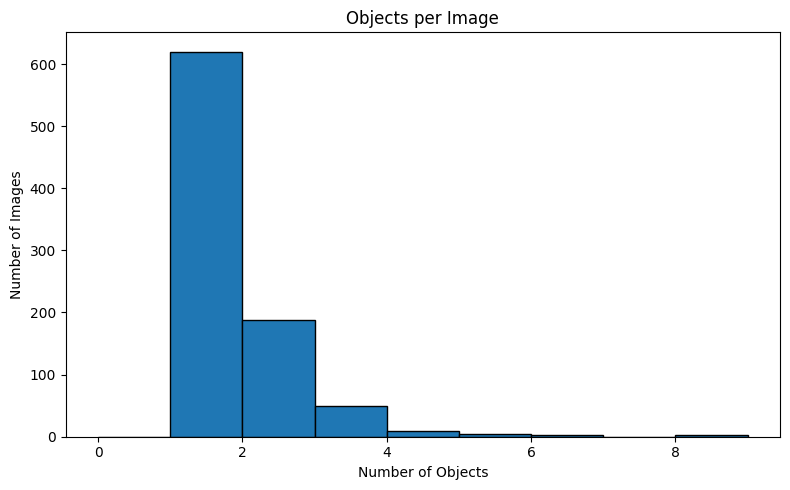

Minimum objects: 1
Maximum objects: 8


In [12]:
plt.figure(figsize=(8, 5))

plt.hist(
    objects_per_image,
    bins=range(0, max(objects_per_image) + 2),
    edgecolor="black"
)

plt.title("Objects per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

print("Minimum objects:", min(objects_per_image))
print("Maximum objects:", max(objects_per_image))

## 9. Dataset Quality Validation

Before converting annotations to YOLO format, the dataset is checked for common data quality problems.

The validation includes:
- Missing images.
- Missing annotations.
- Corrupted images.
- Invalid XML files.
- Invalid bounding box coordinates.
- Unknown object classes.

All six validation checks returned zero errors.

The dataset passed the implemented validation checks and can proceed to annotation conversion.

In [13]:
from PIL import Image
import xml.etree.ElementTree as ET
import os

missing_images = []
missing_annotations = []
corrupted_images = []
invalid_boxes = []
invalid_xml = []
unknown_classes = []

class_names = {
    "trafficlight", "stop", "speedlimit", "crosswalk"
}

image_map = {
    os.path.splitext(f)[0]: f for f in images
}
annotation_map = {
    os.path.splitext(f)[0]: f for f in annotations
}

for name in annotation_map:
    if name not in image_map:
        missing_images.append(name)

for name in image_map:
    if name not in annotation_map:
        missing_annotations.append(name)

for name in image_map:
    image_file = os.path.join(images_path, image_map[name])

    try:
        with Image.open(image_file) as img:
            width, height = img.size
            img.verify()
    except Exception:
        corrupted_images.append(name)
        continue

    if name not in annotation_map:
        continue

    xml_file = os.path.join(
        annotations_path, annotation_map[name]
    )

    try:
        root = ET.parse(xml_file).getroot()

        for obj in root.findall("object"):
            label = obj.findtext("name")

            if label not in class_names:
                unknown_classes.append((name, label))

            bbox = obj.find("bndbox")
            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            if not (
                0 <= xmin < xmax <= width
                and 0 <= ymin < ymax <= height
            ):
                invalid_boxes.append(name)

    except (ET.ParseError, ValueError, TypeError, AttributeError):
        invalid_xml.append(name)

print("Missing images:", len(missing_images))
print("Missing annotations:", len(missing_annotations))
print("Corrupted images:", len(corrupted_images))
print("Invalid XML:", len(invalid_xml))
print("Invalid bounding boxes:", len(invalid_boxes))
print("Unknown classes:", len(unknown_classes))

Missing images: 0
Missing annotations: 0
Corrupted images: 0
Invalid XML: 0
Invalid bounding boxes: 0
Unknown classes: 0



## 10. Annotation Conversion to YOLO Format

The Pascal VOC XML annotations are converted into YOLO TXT format.

Each annotated object is represented by five values:

`class_id x_center y_center width height`

The bounding box coordinates are normalized relative to image dimensions.

The class mapping is defined as follows:

| Class ID | Class Name |
|---|---|
| 0 | trafficlight |
| 1 | stop |
| 2 | speedlimit |
| 3 | crosswalk |

The conversion produces one TXT annotation file for each image.


In [14]:
import os

yolo_labels_path = "/content/yolo_labels"
os.makedirs(yolo_labels_path, exist_ok=True)

class_map = {
    "trafficlight": 0,
    "stop": 1,
    "speedlimit": 2,
    "crosswalk": 3
}

print("YOLO labels folder:", yolo_labels_path)
print("Classes:", class_map)

YOLO labels folder: /content/yolo_labels
Classes: {'trafficlight': 0, 'stop': 1, 'speedlimit': 2, 'crosswalk': 3}


In [15]:
import xml.etree.ElementTree as ET

for annotation in annotations:
    xml_file = os.path.join(annotations_path, annotation)
    root = ET.parse(xml_file).getroot()

    image_name = os.path.splitext(annotation)[0]
    image_file = os.path.join(
        images_path, image_map[image_name]
    )

    with Image.open(image_file) as img:
        img_width, img_height = img.size

    yolo_lines = []

    for obj in root.findall("object"):
        class_name = obj.findtext("name")
        class_id = class_map[class_name]

        bbox = obj.find("bndbox")

        xmin = float(bbox.findtext("xmin"))
        ymin = float(bbox.findtext("ymin"))
        xmax = float(bbox.findtext("xmax"))
        ymax = float(bbox.findtext("ymax"))

        x_center = ((xmin + xmax) / 2) / img_width
        y_center = ((ymin + ymax) / 2) / img_height
        box_width = (xmax - xmin) / img_width
        box_height = (ymax - ymin) / img_height

        yolo_lines.append(
            f"{class_id} {x_center:.6f} "
            f"{y_center:.6f} {box_width:.6f} "
            f"{box_height:.6f}"
        )

    txt_file = os.path.join(
        yolo_labels_path, image_name + ".txt"
    )

    with open(txt_file, "w") as f:
        f.write("\n".join(yolo_lines))

print("Conversion completed!")
print("YOLO labels created:", len(os.listdir(yolo_labels_path)))

Conversion completed!
YOLO labels created: 877


In [16]:
import xml.etree.ElementTree as ET

for annotation in annotations:
    xml_file = os.path.join(annotations_path, annotation)
    root = ET.parse(xml_file).getroot()

    image_name = os.path.splitext(annotation)[0]
    image_file = os.path.join(
        images_path, image_map[image_name]
    )

    with Image.open(image_file) as img:
        img_width, img_height = img.size

    yolo_lines = []

    for obj in root.findall("object"):
        class_name = obj.findtext("name")
        class_id = class_map[class_name]

        bbox = obj.find("bndbox")

        xmin = float(bbox.findtext("xmin"))
        ymin = float(bbox.findtext("ymin"))
        xmax = float(bbox.findtext("xmax"))
        ymax = float(bbox.findtext("ymax"))

        x_center = ((xmin + xmax) / 2) / img_width
        y_center = ((ymin + ymax) / 2) / img_height
        box_width = (xmax - xmin) / img_width
        box_height = (ymax - ymin) / img_height

        yolo_lines.append(
            f"{class_id} {x_center:.6f} "
            f"{y_center:.6f} {box_width:.6f} "
            f"{box_height:.6f}"
        )

    txt_file = os.path.join(
        yolo_labels_path, image_name + ".txt"
    )

    with open(txt_file, "w") as f:
        f.write("\n".join(yolo_lines))

print("Conversion completed!")
print("YOLO labels created:", len(os.listdir(yolo_labels_path)))

Conversion completed!
YOLO labels created: 877


In [17]:
sample_label = os.path.join(
    yolo_labels_path, "road0.txt"
)

with open(sample_label, "r") as f:
    print("road0.txt:")
    print(f.read())

print(
    "\nTotal TXT files:",
    len([
        f for f in os.listdir(yolo_labels_path)
        if f.endswith(".txt")
    ])
)

road0.txt:
0 0.573034 0.367500 0.411985 0.425000

Total TXT files: 877



## 11. Dataset Splitting

The dataset is randomly divided into training, validation, and test subsets using a fixed random seed of 42.

The split proportions are:
- Training: 70%.
- Validation: 20%.
- Testing: 10%.

| Dataset Split | Number of Images |
|---|---:|
| Training | 613 |
| Validation | 176 |
| Testing | 88 |

The training set is used to train the YOLO model, the validation set is used to monitor training performance, and the test set is reserved for final evaluation.


In [18]:
import os
import random
import shutil

output_path = "/content/road-sign-dataset"

for split in ["train", "val", "test"]:
    os.makedirs(
        os.path.join(output_path, "images", split),
        exist_ok=True
    )
    os.makedirs(
        os.path.join(output_path, "labels", split),
        exist_ok=True
    )

random.seed(42)
shuffled_images = images.copy()
random.shuffle(shuffled_images)

n = len(shuffled_images)

train_end = int(n * 0.7)
val_end = int(n * 0.9)

splits = {
    "train": shuffled_images[:train_end],
    "val": shuffled_images[train_end:val_end],
    "test": shuffled_images[val_end:]
}

for split, filenames in splits.items():
    for filename in filenames:
        name = os.path.splitext(filename)[0]

        shutil.copy2(
            os.path.join(images_path, filename),
            os.path.join(output_path, "images", split, filename)
        )

        shutil.copy2(
            os.path.join(yolo_labels_path, name + ".txt"),
            os.path.join(output_path, "labels", split, name + ".txt")
        )

    print(f"{split}: {len(filenames)} images")

train: 613 images
val: 176 images
test: 88 images



## 12. YOLO Dataset Configuration

The `dataset.yaml` file defines the dataset location, training and validation directories, and supported object classes.

It is required by Ultralytics YOLO to correctly load the prepared dataset during model training.


In [19]:
yaml_content = """path: /content/road-sign-dataset
train: images/train
val: images/val
test: images/test

nc: 4

names:
  0: trafficlight
  1: stop
  2: speedlimit
  3: crosswalk
"""

yaml_path = os.path.join(output_path, "dataset.yaml")

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("Created:", yaml_path)
print(yaml_content)

Created: /content/road-sign-dataset/dataset.yaml
path: /content/road-sign-dataset
train: images/train
val: images/val
test: images/test

nc: 4

names:
  0: trafficlight
  1: stop
  2: speedlimit
  3: crosswalk




## 13. Dataset Structure Verification

The final directory structure is checked to confirm that all images and annotation files are correctly organized.

Each dataset split contains the same number of images and corresponding TXT labels.

The existence of the `dataset.yaml` configuration file is also verified.


In [20]:
for split in ["train", "val", "test"]:
    image_dir = os.path.join(output_path, "images", split)
    label_dir = os.path.join(output_path, "labels", split)

    image_count = len(os.listdir(image_dir))
    label_count = len(os.listdir(label_dir))

    print(
        f"{split}: {image_count} images, "
        f"{label_count} labels"
    )

print("\nDataset YAML exists:",
      os.path.exists(yaml_path))

train: 613 images, 613 labels
val: 176 images, 176 labels
test: 88 images, 88 labels

Dataset YAML exists: True



## 14. Class Distribution Across Dataset Splits

The number of annotated objects is calculated for each dataset subset.

| Class | Train | Validation | Test |
|---|---:|---:|---:|
| trafficlight | 129 | 23 | 18 |
| stop | 56 | 26 | 9 |
| speedlimit | 545 | 157 | 81 |
| crosswalk | 147 | 28 | 25 |

All four classes are represented in the training, validation, and test subsets.

However, the number of stop sign objects in the test set is relatively small, which may affect the reliability of class-specific evaluation results.


In [21]:
from collections import Counter
import pandas as pd
import os

class_names = [
    "trafficlight",
    "stop",
    "speedlimit",
    "crosswalk"
]

split_counts = {}

for split in ["train", "val", "test"]:
    label_dir = os.path.join(output_path, "labels", split)
    counts = Counter()

    for filename in os.listdir(label_dir):
        if not filename.endswith(".txt"):
            continue

        with open(os.path.join(label_dir, filename)) as f:
            for line in f:
                if line.strip():
                    class_id = int(line.split()[0])
                    counts[class_names[class_id]] += 1

    split_counts[split] = counts

df_split = pd.DataFrame(split_counts).fillna(0).astype(int)
df_split = df_split.reindex(class_names, fill_value=0)

print(df_split)
print("\nTotal objects:", df_split.sum().sum())

              train  val  test
trafficlight    129   23    18
stop             56   26     9
speedlimit      545  157    81
crosswalk       147   28    25

Total objects: 1244



### Dataset Split Visualization

A grouped bar chart is created to compare class distributions across the training, validation, and test subsets.

The chart confirms that speed limit signs are the most common objects in every subset, while stop signs are less frequent.


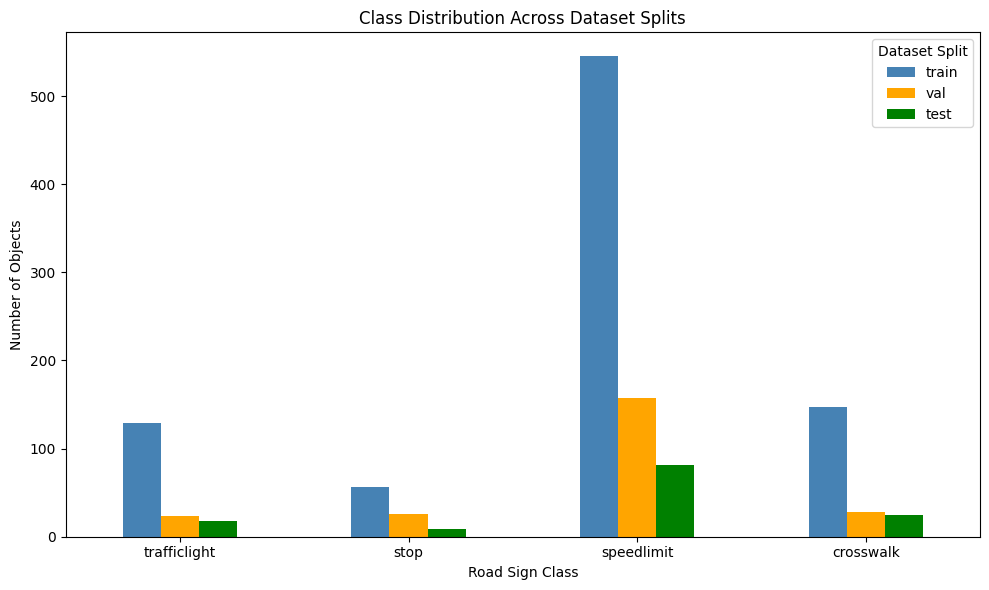

In [22]:
ax = df_split.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange", "green"]
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Road Sign Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()

plt.savefig("split_distribution.png", dpi=300)
plt.show()


## 15. Exporting the Prepared Dataset

The prepared YOLO dataset is compressed into a ZIP archive for storage and sharing with the machine learning engineer.

The archive contains:
- Training, validation, and test images.
- YOLO TXT annotation files.
- The `dataset.yaml` configuration file.

This ensures that the same dataset can be used for reproducible model training.


In [23]:
archive_path = shutil.make_archive(
    "/content/road-sign-dataset",
    "zip",
    root_dir="/content",
    base_dir="road-sign-dataset"
)

print("Archive created:", archive_path)
print(
    "Archive size:",
    round(os.path.getsize(archive_path) / (1024 * 1024), 2),
    "MB"
)

Archive created: /content/road-sign-dataset.zip
Archive size: 217.95 MB


In [24]:
from google.colab import files

files.download("/content/road-sign-dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Visual Verification of YOLO Annotations

To verify the correctness of the XML-to-YOLO conversion, sample images are displayed with bounding boxes reconstructed from the normalized YOLO coordinates. This allows us to confirm that the annotations match the actual road signs.

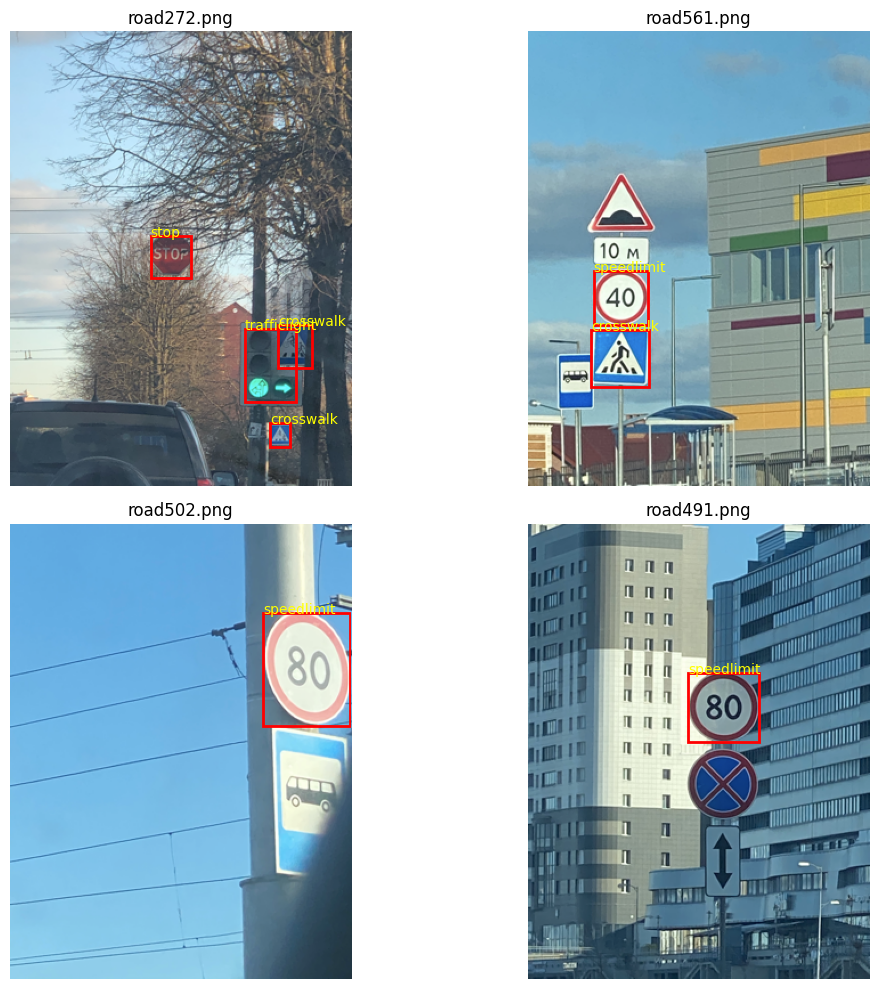

In [26]:

import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

dataset_dir = "/content/road-sign-dataset"
images_dir = os.path.join(dataset_dir, "images", "train")
labels_dir = os.path.join(dataset_dir, "labels", "train")

class_names = ["trafficlight", "stop", "speedlimit", "crosswalk"]

image_files = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.seed(42)
samples = random.sample(image_files, min(4, len(image_files)))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, filename in zip(axes.flat, samples):
    image = Image.open(os.path.join(images_dir, filename)).convert("RGB")
    width, height = image.size

    label_path = os.path.join(
        labels_dir, os.path.splitext(filename)[0] + ".txt"
    )

    ax.imshow(image)

    with open(label_path, "r") as f:
        for line in f:
            class_id, xc, yc, bw, bh = map(float, line.split())

            xmin = (xc - bw / 2) * width
            ymin = (yc - bh / 2) * height

            rect = patches.Rectangle(
                (xmin, ymin),
                bw * width,
                bh * height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)
            ax.text(
                xmin, ymin,
                class_names[int(class_id)],
                color="yellow",
                fontsize=10
            )

    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()


### Dataset Split Verification

The dataset was divided into training (70%), validation (20%), and testing (10%) subsets.

To ensure reliable and reproducible experiments, the dataset splits are checked for duplicate filenames, matching image and annotation files, and the presence of the YOLO configuration file (`dataset.yaml`).

In [27]:
import os

dataset_dir = "/content/road-sign-dataset"
splits = ["train", "val", "test"]
split_files = {}

for split in splits:
    image_dir = os.path.join(dataset_dir, "images", split)
    label_dir = os.path.join(dataset_dir, "labels", split)

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    labels = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.endswith(".txt")
    }

    split_files[split] = images

    print(f"{split}: {len(images)} images, {len(labels)} labels")
    print("Matching images and labels:", images == labels)

print("\nDuplicates between splits:")
print("Train / Val:", len(split_files["train"] & split_files["val"]))
print("Train / Test:", len(split_files["train"] & split_files["test"]))
print("Val / Test:", len(split_files["val"] & split_files["test"]))

yaml_path = os.path.join(dataset_dir, "dataset.yaml")
print("\nDataset YAML exists:", os.path.exists(yaml_path))

if os.path.exists(yaml_path):
    with open(yaml_path, "r") as f:
        print("\nDataset configuration:")
        print(f.read())

train: 613 images, 613 labels
Matching images and labels: True
val: 176 images, 176 labels
Matching images and labels: True
test: 88 images, 88 labels
Matching images and labels: True

Duplicates between splits:
Train / Val: 0
Train / Test: 0
Val / Test: 0

Dataset YAML exists: True

Dataset configuration:
path: /content/road-sign-dataset
train: images/train
val: images/val
test: images/test

nc: 4

names:
  0: trafficlight
  1: stop
  2: speedlimit
  3: crosswalk



## 16. Image Preprocessing Configuration

Before training the YOLO model, images must be prepared using a consistent input size and normalization procedure.

The model will use an input resolution of 640 × 640 pixels. Ultralytics YOLO automatically resizes images while preserving their aspect ratio through letterboxing and normalizes pixel values during training.

The original dataset images and YOLO annotations will remain unchanged.

In [28]:
import os
import yaml

dataset_path = "/content/road-sign-dataset"
yaml_path = os.path.join(dataset_path, "dataset.yaml")

image_size = 640

with open(yaml_path, "r") as f:
    dataset_config = yaml.safe_load(f)

print("Image size:", image_size)
print("Dataset path:", dataset_path)
print("Number of classes:", dataset_config["nc"])
print("Class names:", dataset_config["names"])

Image size: 640
Dataset path: /content/road-sign-dataset
Number of classes: 4
Class names: {0: 'trafficlight', 1: 'stop', 2: 'speedlimit', 3: 'crosswalk'}


## 17. Data Augmentation Configuration

Data augmentation is used to improve the generalization ability of the YOLO model.

The training pipeline will include brightness and color adjustments, small rotations, scaling, translations, and horizontal flips.

Augmentations will be applied to training images only. Validation and test images will remain unaugmented to ensure reliable model evaluation.

Bounding box coordinates will be transformed automatically by the Ultralytics YOLO pipeline.

In [29]:
augmentation_config = {
    "imgsz": 640,
    "hsv_h": 0.015,
    "hsv_s": 0.5,
    "hsv_v": 0.3,
    "degrees": 5.0,
    "translate": 0.1,
    "scale": 0.3,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 0.5
}

for parameter, value in augmentation_config.items():
    print(f"{parameter}: {value}")

imgsz: 640
hsv_h: 0.015
hsv_s: 0.5
hsv_v: 0.3
degrees: 5.0
translate: 0.1
scale: 0.3
fliplr: 0.5
flipud: 0.0
mosaic: 0.5


## 18. Preprocessing and Annotation Verification

Before model training, the dataset structure and normalized bounding box coordinates are verified.

This ensures that every image has a corresponding annotation file and that all YOLO bounding boxes contain valid normalized coordinates.

In [33]:
from pathlib import Path

total_images = 0
total_labels = 0
invalid_boxes = 0

for split in ["train", "val", "test"]:
    image_dir = Path(dataset_path) / "images" / split
    label_dir = Path(dataset_path) / "labels" / split

    images = list(image_dir.glob("*.png"))
    total_images += len(images)

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            print("Missing label:", image_path.name)
            continue

        total_labels += 1

        for line in label_path.read_text().splitlines():
            values = line.split()

            if len(values) != 5:
                invalid_boxes += 1
                continue

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            if not (
                0 <= class_id < 4
                and 0 < w <= 1
                and 0 < h <= 1
                and 0 <= x - w / 2
                and x + w / 2 <= 1
                and 0 <= y - h / 2
                and y + h / 2 <= 1
            ):
                invalid_boxes += 1

print("Total images:", total_images)
print("Matching labels:", total_labels)
print("Invalid bounding boxes:", invalid_boxes)

Total images: 877
Matching labels: 877
Invalid bounding boxes: 0


In [31]:
from pathlib import Path

for split in ["train", "val", "test"]:
    label_dir = Path(dataset_path) / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        for line_number, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            values = line.split()

            try:
                if len(values) != 5:
                    raise ValueError("Incorrect number of values")

                class_id = int(values[0])
                x, y, w, h = map(float, values[1:])

                valid = (
                    0 <= class_id < 4
                    and 0 < w <= 1
                    and 0 < h <= 1
                    and 0 <= x - w / 2
                    and x + w / 2 <= 1
                    and 0 <= y - h / 2
                    and y + h / 2 <= 1
                )

                if not valid:
                    print(
                        f"File: {label_path.name}, "
                        f"Split: {split}, "
                        f"Line: {line_number}"
                    )
                    print("Values:", line)
                    print()

            except ValueError as e:
                print(label_path.name, line_number, line, e)

File: road701.txt, Split: train, Line: 1
Values: 2 0.891667 0.383750 0.216667 0.182500

File: road681.txt, Split: train, Line: 2
Values: 3 0.033333 0.703750 0.066667 0.052500

File: road554.txt, Split: train, Line: 2
Values: 3 0.033333 0.926250 0.066667 0.082500

File: road472.txt, Split: train, Line: 1
Values: 2 0.158333 0.631250 0.316667 0.272500

File: road275.txt, Split: test, Line: 3
Values: 3 0.981667 0.741250 0.036667 0.157500



## 19. Bounding Box Coordinate Correction

Five bounding boxes were identified with coordinates slightly outside the normalized image boundaries.

These inconsistencies were caused by floating-point rounding during the conversion from Pascal VOC XML annotations to YOLO format.

To preserve all annotated road signs, the affected bounding boxes are corrected by clipping their coordinates to the valid range [0, 1].

In [32]:
from pathlib import Path

fixed_boxes = 0

for split in ["train", "val", "test"]:
    label_dir = Path(dataset_path) / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        lines = label_path.read_text().splitlines()
        corrected_lines = []

        for line in lines:
            values = line.split()

            if len(values) != 5:
                corrected_lines.append(line)
                continue

            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])

            x1 = x - w / 2
            y1 = y - h / 2
            x2 = x + w / 2
            y2 = y + h / 2

            if (
                x1 < 0 or y1 < 0
                or x2 > 1 or y2 > 1
            ):
                x1 = max(0.0, min(1.0, x1))
                y1 = max(0.0, min(1.0, y1))
                x2 = max(0.0, min(1.0, x2))
                y2 = max(0.0, min(1.0, y2))

                x = (x1 + x2) / 2
                y = (y1 + y2) / 2
                w = x2 - x1
                h = y2 - y1

                fixed_boxes += 1

            corrected_lines.append(
                f"{class_id} {x:.8f} {y:.8f} {w:.8f} {h:.8f}"
            )

        label_path.write_text(
            "\n".join(corrected_lines) + "\n"
        )

print("Corrected bounding boxes:", fixed_boxes)

Corrected bounding boxes: 5


## 20. Conclusion

The Road Sign Detection dataset was successfully downloaded, explored, validated, and prepared for YOLO model training.

The dataset contains **877 images and 1,244 annotated objects** across four classes: trafficlight, stop, speedlimit, and crosswalk.

The original Pascal VOC XML annotations were converted into YOLO TXT format. The dataset was divided into three subsets: **613 training images (70%), 176 validation images (20%), and 88 testing images (10%)**. A fixed random seed was used to ensure reproducibility, and no duplicate images were found across the subsets.

Dataset validation confirmed that all images have matching annotation files. Five bounding boxes with minor coordinate inconsistencies caused by rounding were identified and corrected. After correction, **no invalid bounding boxes remained**.

Image preprocessing parameters were configured, including an input resolution of 640 × 640 pixels and normalization through the YOLO pipeline. Data augmentation settings were also prepared, including brightness adjustments, rotation, scaling, translation, and horizontal flipping.

The prepared dataset is ready for the next stage: configuring, training, and evaluating the YOLO object detection model. The augmentation settings will be applied and verified during model training.